# 第 09 步：原始动量的五分组收益检验

<!-- SNAPSHOT_NOTE -->

## 数据准备

本页记录完整快照上的实际运行。从 GitHub 克隆源码后，先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。

## 目标、前置与运行命令

前两步用 Rank IC 观察了完整横截面的排名关系。本步换一种更直观的检查：先按信号日原始动量把股票分成五组，再观察各组下一持有期的理论平均收益。重点是区分“高组减低组为正”和“五组收益随得分逐级上升”这两个不同命题。

样本仍使用 40 只 SYN 模拟股票，保持 20 期原始动量、月度调仓日期、次日开盘到下次调仓开盘标签，以及开发 2020—2022、验证 2023、测试 2024—2025 的时间划分。数据与图中的规律仅用于训练研究方法。

前置内容是 [月度 IC 与时间边界](../08_monthly_ic_icir/README.md)。在仓库根目录运行：

```powershell
.\.venv\Scripts\python.exe .\examples\09_quintile_returns.py
```

入口是 [09_quintile_returns.py](../../examples/09_quintile_returns.py)。本步直接读取输入行情并调用 [build_forward_labels](../../src/ashare_lab/research.py)，不依赖第 08 步 CSV 已经存在。若当前环境尚无绘图库，先执行一次 ` .\.venv\Scripts\python.exe -m pip install -e ".[plots]" `。

## 先分组，再关联未来标签

将当前有效动量数量记为 \(N_T\)，由低到高的平均秩记为 \(r_{i,T}\)：

$$G_{i,T}=\left\lfloor\frac{(r_{i,T}-1)\times5}{N_T}\right\rfloor+1.$$

G1 定义为低动量组，G5 定义为高动量组。这个编号与第 07 步“第 1 名表示最大值”的降序名次不同，不能把名次 1 误写成 G1 高分组。

先用信号日可见的全部有效因子形成分组，随后才关联未来收益：

```python
cross = factor_values.loc[factor_values["date"] == signal_date].dropna(
    subset=["momentum_20"]
).copy()
rank_low_to_high = cross["momentum_20"].rank(method="average", ascending=True)
cross["group"] = (
    np.floor((rank_low_to_high - 1) * n_groups / len(cross)) + 1
).astype(int)
paired = cross.merge(period_labels, on=["date", "symbol"], how="left",
                     validate="one_to_one")
```

第一部分只让历史动量影响组别；最后一行的未来标签只负责事后评价。不能先删除未来收益缺失的股票，再根据剩余股票重新分组，否则未来数据可得性就会改变信号日的名单。

平均秩使同分股票得到一致处理。当前模拟数据每期 40 个动量互不相同，因此五组各 8 只；若存在大量并列值，这个公式可能产生大小不等或空组。一般输入不一定能得到严格等人数的五分组，也不应按代码拆开同分股票来制造整齐结果。

## 理论组收益与组间收益差

假设组内股票在理论入场时按金额等权，此后持有至理论退出时点。组内收益为：

$$R_{g,T}=\frac1{n_{g,T}}\sum_{i\in g}R^{fwd}_{i,T}.$$

持有期内不进行每日重新等权。相同初始金额、持有不交易时，期末组合收益等于成员持有期收益的算术平均。

组内所有已分配成员的标签必须完整：

```python
n_assigned = len(members)
n_valid = int(members["forward_return"].notna().sum())
status = "ok" if n_assigned > 0 and n_valid == n_assigned else "incomplete_group"
group_return = members["forward_return"].mean() if status == "ok" else np.nan
```

同时记录 `n_assigned` 与 `n_valid`，避免默认 `mean()` 自动跳过缺失成员。空组或缺少任一成员标签时，该组收益留空；比较阶段只保留五组都完整的共同月份。

进一步定义：

$$Spread_T=R_{5,T}-R_{1,T}.$$

`spread * 100` 表示百分点差。例如 `0.02` 表示高组收益比低组高 2 个百分点。这个量没有定义卖空资金、保证金、借券费用、交易成本和组合资本基准，因此它不能称为真实多空净收益，也不能直接对 `1 + spread` 连乘画出交易净值。

## 首期成员与实际结果

首期信号为 `2020-01-31`，标签入场为 `2020-02-03` 开盘，退出为 `2020-03-02` 开盘。

| 分组 | 成员数 | 理论持有期平均收益 |
|---|---:|---:|
| G1 | 8 | 6.3612316152% |
| G2 | 8 | 2.0983036085% |
| G3 | 8 | -0.1335023253% |
| G4 | 8 | 2.2093751156% |
| G5 | 8 | 2.5553973738% |

首期得到 `G5-G1 = -0.038058342414769505`，即 **-3.8058342415 个百分点**。这也是需要保留的结果，不能因全期平均差为正，就隐去这个高组落后低组的月份。

成员表中，首期 G1 是 `SYN006、SYN016、SYN038、SYN021、SYN023、SYN039、SYN027、SYN035`；G5 是 `SYN004、SYN018、SYN001、SYN029、SYN025、SYN034、SYN008、SYN037`。通过这些代码可以回到原始标签，逐项重算组均值。

## 完整区间的结果

本次得到 66 个完整可比持有期、330 行组收益和 2640 行成员记录。各期每组都是 8 只股票，但这是已核实的数据特征，不是任意数据都具有的保证。

从 [group_summary.csv](../../runs/first_demo_20261107/lesson09_quintile_returns/group_summary.csv) 得到各阶段的月度持有期简单平均：

| 阶段 | G1 | G2 | G3 | G4 | G5 |
|---|---:|---:|---:|---:|---:|
| 开发期，34 期 | 0.052582% | 1.522523% | 0.538767% | 0.699856% | 0.153327% |
| 验证期，10 期 | -0.242356% | -0.868102% | -0.037047% | 0.447286% | 2.171763% |
| 测试期，22 期 | -0.904799% | -0.466987% | 0.038322% | 0.175631% | 0.653955% |

这些数先按月计算组收益，再对月份等权平均，既不是所有股票收益混在一起的任意加权，也不是年化收益率。

| 阶段 | 平均 G5-G1，百分点 | 差值样本标准差，百分点 | 正差月份 | 均值是否逐组不下降 |
|---|---:|---:|---:|---|
| 开发期 | 0.100744 | 4.179790 | 20/34 | 否 |
| 验证期 | 2.414119 | 2.907107 | 7/10 | 否 |
| 测试期 | 1.558754 | 4.088409 | 15/22 | 是 |

开发期 G5 高于 G1，但 G2 反而最高，说明“首尾差为正”不等于“组均值单调”。测试期在这份模拟样本中恰好逐组上升，我将这一观察保留为样本描述，不扩展为真实市场定律。

按信号年份核对的平均差分别为：2020 年 `-0.486137` 个百分点、2021 年 `-0.194689`、2022 年 `1.159523`、2023 年 `2.414119`、2024 年 `0.480323`、2025 年 `2.852872`。年份之间的变化也提示，需要继续观察时期差异。

## 图表与输出文件

“组内算术平均”可以用一个两股票的小例子复核：入场时各投入一百元，一只涨百分之十，另一只跌百分之十，退出时分别值一百一十元和九十元，总资产仍为二百元，组合收益为零，正好等于两只收益的算术平均。这与同一笔资金先涨后跌不同，后者才需要跨时间连乘，并得到负百分之一。横截面组合聚合与单资产时间复利是两种运算。

每个新信号月重新形成理论组，但本课没有维护跨月现金账户，也没有追踪旧组换到新组需要多少订单。因此，分组曲线与真实策略之间仍然有明确距离。未来的组合回测需要把持仓数量、调仓费用和无法成交的旧仓一起带入下一天，而不是在每个月假设一切可以无成本重置。

采用共同完整月份，是为了让五组平均值在同一批时期上可比。这个规则并不自动解决所有缺失偏差：如果某类股票或某类时期更容易缺少未来价格，完整样本本身也可能有选择性。因此还需同时保留成员、数量和排除状态，使后续研究能够检查这种选择性，而不是把一张没有空缺的图误认为数据已经没有风险。

![我保存的原始动量五分组均值及逐月收益差](../../runs/first_demo_20261107/lesson09_quintile_returns/quintile_returns.png)

阅读上排三个柱图时，先看纵轴“平均持有期收益，非年化”，再看五组排列是否平滑。三个面板使用一致尺度，便于比较阶段差异。下排的纵轴改为百分点差，蓝线是每期差值，橙色虚线是分区均值，空缺没有补零。

| 文件 | 复核用途 |
|---|---|
| [group_membership.csv](../../runs/first_demo_20261107/lesson09_quintile_returns/group_membership.csv) | 核对股票在信号时点所属组别与未来标签 |
| [monthly_group_returns.csv](../../runs/first_demo_20261107/lesson09_quintile_returns/monthly_group_returns.csv) | 核对 `n_assigned`、`n_valid`、收益和状态 |
| [monthly_spread.csv](../../runs/first_demo_20261107/lesson09_quintile_returns/monthly_spread.csv) | 保留全部 72 个信号月，排除月份留空 |
| [spread_summary.csv](../../runs/first_demo_20261107/lesson09_quintile_returns/spread_summary.csv) | 复核差值均值、样本标准差、正值占比与单调标记 |
| [yearly_spread.csv](../../runs/first_demo_20261107/lesson09_quintile_returns/yearly_spread.csv) | 检查整体平均是否掩盖年份差异 |

本步沿用前一步的四个跨分区排除月和两个末尾不完整月。`monthly_spread.csv` 的 `excluded_label_or_group` 是本课的合并状态，具体时间排除原因可以回查第 08 步月度 IC 审计表。

## 常见错误、验收与结论

- 先按未来收益筛股票，再重算分组，会让未来信息影响分组。
- 缺失标签时若让 `mean()` 自动跳过成员，会改变事先定义的组内组合；因此我选择整组留空。
- 只看 G5-G1，不看 G2—G4，可能把非单调的关系误写成完整排序能力。
- 将 `positive_share` 称为交易胜率，会混淆理论组间比较与实际订单盈亏。
- 将百分点差当成可以直接复利的收益，会忽略多空资本与成本定义。

验收包括：首期五组各 8 只；首期差值为约 -3.805834 个百分点；完整比较期为 66；成员数与组数能够勾稽；未来标签没有参与分组；图表空缺保留。本步将因子检验扩展为可回溯的分组实验，得到理论结构读数，后续才进入更多因子的构建和实际组合回测。

## 完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/09_quintile_returns.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
"""第九课：原始动量五分组、理论组收益与 G5-G1 收益差；模拟数据。"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
from ashare_lab.config import load_config
from ashare_lab.research import build_forward_labels

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

project_dir = Path(__file__).resolve().parents[1]
data_path = project_dir / "runs" / "first_demo_20261107" / "input" / "prices.csv"
prices = pd.read_csv(data_path, dtype={"symbol": "string"}, parse_dates=["date"])
calendar = pd.read_csv(data_path.with_name("calendar.csv"), parse_dates=["date"])
days = pd.DatetimeIndex(calendar["date"])
config = load_config(project_dir / "configs" / "baseline.json")
lookback, n_groups = config["lookback"], 5

# 1. 与前几课相同：只使用各股票当时已经知道的历史行情计算原始动量。
factor_tables = []
for symbol, stock in prices.groupby("symbol", sort=True):
    stock = stock.sort_values("date").set_index("date").reindex(days).reset_index()
    stock["symbol"] = symbol
    close = stock["adj_close"].where(stock["adj_close"] > 0)
    count = close.rolling(lookback + 1, min_periods=lookback + 1).count()
    stock["momentum_20"] = (close / close.shift(lookback) - 1).where(count == lookback + 1)
    factor_tables.append(stock[["date", "symbol", "momentum_20"]])
factor_values = pd.concat(factor_tables, ignore_index=True)

# 2. 复用项目中的标签函数：次日开盘到下次调仓开盘；剔除跨分区及末尾不完整标签。
labels = build_forward_labels(prices, factor_values, days, config)

# 3. 先用信号日因子确定组别，再关联未来收益。未来价格不影响股票的分组。
member_tables, group_records = [], []
for signal_date, period_labels in labels.groupby("date", sort=True):
    split = period_labels["split"].iloc[0]
    cross = factor_values.loc[factor_values["date"] == signal_date].dropna(
        subset=["momentum_20"]
    ).copy()
    if len(cross) < n_groups or cross["momentum_20"].nunique() < 2:
        for group in range(1, n_groups + 1):
            group_records.append(dict(date=signal_date, split=split, group=group,
                n_assigned=0, n_valid=0, group_return=np.nan, status="insufficient_factor"))
        continue

    # 低动量排在前面；并列因子使用平均秩，不用股票代码拆开同分股票。
    rank_low_to_high = cross["momentum_20"].rank(method="average", ascending=True)
    cross["group"] = (
        np.floor((rank_low_to_high - 1) * n_groups / len(cross)) + 1
    ).astype(int)
    paired = cross.merge(period_labels, on=["date", "symbol"], how="left",
                         validate="one_to_one")
    member_tables.append(paired)

    # 4. 每组入场时等权、持有到退出，理论组收益为成员收益的算术平均。
    # 组内任一股票缺失收益时，该组留空；不靠删除缺失成员来重分组或补零。
    for group in range(1, n_groups + 1):
        members = paired.loc[paired["group"] == group]
        n_assigned = len(members)
        n_valid = int(members["forward_return"].notna().sum())
        status = "ok" if n_assigned > 0 and n_valid == n_assigned else "incomplete_group"
        group_return = members["forward_return"].mean() if status == "ok" else np.nan
        group_records.append(dict(date=signal_date, split=split, group=group,
            n_assigned=n_assigned, n_valid=n_valid, group_return=group_return, status=status))

### 完整实现 · 单元 2

In [3]:
membership = pd.concat(member_tables, ignore_index=True)
group_table = pd.DataFrame(group_records)

# 5. 将每期五组排成五列，只在五组收益都完整的共同月份上作比较。
wide = group_table.pivot(index=["date", "split"], columns="group", values="group_return")
comparison = wide.dropna(subset=[1, 2, 3, 4, 5]).reset_index()

### 完整实现 · 单元 3

In [4]:
if comparison.empty:
    raise ValueError("没有完整的五分组持有期，请检查因子分散程度、组数和未来收益覆盖。")

### 完整实现 · 单元 4

In [5]:
comparison["spread"] = comparison[5] - comparison[1]

# 6. 先逐月计算各组收益，再在开发/验证/测试期内对月份取算术平均。
used_groups = group_table.loc[group_table["date"].isin(comparison["date"])].copy()
group_summary = used_groups.groupby(["split", "group"], sort=False).agg(
    n_months=("group_return", "count"), mean_return=("group_return", "mean")
).reset_index()

spread_records = []
for split in config["splits"]:
    values = comparison.loc[comparison["split"] == split, "spread"]
    means = group_summary.loc[group_summary["split"] == split].set_index("group")["mean_return"]
    ordered_means = means.reindex([1, 2, 3, 4, 5])
    monotonic = (bool((ordered_means.diff().dropna() >= 0).all())
                 if ordered_means.notna().all() else None)
    spread_records.append(dict(split=split, n_months=len(values),
        mean_spread=values.mean(), spread_std=values.std(ddof=1),
        positive_months=int((values > 0).sum()), positive_share=(values > 0).mean(),
        increasing_group_means=monotonic))
spread_summary = pd.DataFrame(spread_records)
yearly_spread = comparison.groupby(comparison["date"].dt.year)["spread"].agg(
    n_months="count", mean_spread="mean"
).reset_index().rename(columns={"date": "signal_year"})

# 7. 保存成员、组收益和汇总。完整月度差值表保留被排除月份的空值。
all_months = pd.Series(days, index=days).groupby(days.to_period("M")).last()
all_months = pd.DatetimeIndex(all_months.to_numpy())
review_dates = all_months[(all_months >= pd.Timestamp(config["start"])) &
                         (all_months <= pd.Timestamp(config["end"]))]
monthly = comparison.rename(columns={g: f"G{g}" for g in range(1, 6)})
monthly = monthly.set_index("date").reindex(review_dates).rename_axis("date").reset_index()
monthly["status"] = np.where(monthly["spread"].notna(), "ok", "excluded_label_or_group")
output_dir = data_path.parent.parent / "lesson09_quintile_returns"
output_dir.mkdir(parents=True, exist_ok=True)
for name, frame in {
    "group_membership": membership, "monthly_group_returns": group_table,
    "group_summary": group_summary, "monthly_spread": monthly,
    "spread_summary": spread_summary, "yearly_spread": yearly_spread,
}.items():
    frame.to_csv(output_dir / f"{name}.csv", index=False, date_format="%Y-%m-%d")

### 完整实现 · 单元 5

In [6]:
# 8. 上排对比各阶段五组平均收益；下排保留每月 G5-G1 的波动与空缺。
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11
fig = plt.figure(figsize=(12, 8.4), layout="constrained")
grid = fig.add_gridspec(2, 3, height_ratios=[1, 1.15])
split_labels = {"development": "开发期", "validation": "验证期", "test": "测试期"}
means_all = group_summary["mean_return"]
lower, upper = min(-0.005, means_all.min() - 0.005), max(0.005, means_all.max() + 0.006)
for column, split in enumerate(config["splits"]):
    ax = fig.add_subplot(grid[0, column])
    block = group_summary.loc[group_summary["split"] == split].set_index("group")
    values = block["mean_return"].reindex([1, 2, 3, 4, 5])
    count = spread_summary.loc[spread_summary["split"] == split, "n_months"].iloc[0]
    ax.bar(range(1, 6), values, color="#3268A8", width=0.65)
    ax.axhline(0, color="#747D86", linewidth=0.8)
    for group, value in values.items():
        if pd.notna(value):
            ax.annotate(f"{value:.2%}", xy=(group, value), xytext=(0, 5 if value >= 0 else -6),
                        textcoords="offset points", ha="center",
                        va="bottom" if value >= 0 else "top", fontsize=10)
    ax.set_title(f"{split_labels.get(split, split)}：{count} 个有效持有期", fontsize=12)
    ax.set_xticks(range(1, 6), [f"G{g}" for g in range(1, 6)])
    ax.set_xlabel("低动量 G1 → 高动量 G5")
    ax.set_ylim(lower, upper)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
    if column == 0:
        ax.set_ylabel("平均持有期收益（非年化）")
    ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

ax = fig.add_subplot(grid[1, :])
# 乘以 100 后以“百分点”显示收益差，避免把理论差值称为真实多空净收益。
ax.plot(monthly["date"], monthly["spread"] * 100, color="#3268A8", marker="o",
        markersize=3, linewidth=1.2, label="每期 G5−G1")
ax.axhline(0, color="#747D86", linewidth=0.9)
for index, (split, bounds) in enumerate(config["splits"].items()):
    block = monthly.loc[monthly["split"] == split]
    mean = spread_summary.loc[spread_summary["split"] == split, "mean_spread"].iloc[0]
    ax.hlines(mean * 100, block["date"].min(), block["date"].max(), color="#B46A31",
              linestyle="--", linewidth=1.3, label="分区平均差值" if index == 0 else None)
    if index > 0:
        ax.axvline(pd.Timestamp(bounds[0]), color="#AEB7BF", linestyle=":", linewidth=0.8)

### 完整实现 · 单元 6

In [7]:
tick_indices = sorted({0, len(monthly) // 3, len(monthly) * 2 // 3, len(monthly) - 1})
ax.set_xticks(monthly["date"].iloc[tick_indices])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_xlim(monthly["date"].iloc[0], monthly["date"].iloc[-1])
ax.set_ylabel("高组减低组的收益差（百分点）")
ax.set_xlabel("信号月份（空缺未补零；收益为次日开盘到下次调仓开盘的理论毛收益）")
ax.legend(loc="upper left", frameon=False, fontsize=10, ncols=2)
ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("原始动量五分组收益检验（模拟数据、未扣成本）", fontsize=17)
fig.savefig(output_dir / "quintile_returns.png", dpi=180)
plt.close(fig)

print("模拟股票池；组内入场等权，期间持有；各持有期算术平均，非年化、未扣成本。")
print("完整持有期数：", len(comparison))
print("组收益行数：", len(group_table))
print("每组股票数量分布：", group_table["n_assigned"].value_counts().to_dict())
print("\n首期五分组（group_return 为小数收益率）：")
print(group_table.loc[group_table["date"] == comparison["date"].min()].to_string(index=False))
print("\n各分区、各组平均持有期收益（小数）：")
print(group_summary.to_string(index=False))
print("\n高组减低组的差值汇总（小数差值乘 100 为百分点，不是交易胜率）：")
print(spread_summary.to_string(index=False))
print("\n按信号年份统计 G5−G1：")
print(yearly_spread.to_string(index=False))
print("\n本课结果目录：", output_dir)
print("G5−G1 仅为理论收益差，未模拟卖空、保证金、资金占用及交易成本。")

模拟股票池；组内入场等权，期间持有；各持有期算术平均，非年化、未扣成本。
完整持有期数： 66
组收益行数： 330
每组股票数量分布： {8: 330}

首期五分组（group_return 为小数收益率）：
      date       split  group  n_assigned  n_valid  group_return status
2020-01-31 development      1           8        8      0.063612     ok
2020-01-31 development      2           8        8      0.020983     ok
2020-01-31 development      3           8        8     -0.001335     ok
2020-01-31 development      4           8        8      0.022094     ok
2020-01-31 development      5           8        8      0.025554     ok

各分区、各组平均持有期收益（小数）：
      split  group  n_months  mean_return
development      1        34     0.000526
development      2        34     0.015225
development      3        34     0.005388
development      4        34     0.006999
development      5        34     0.001533
 validation      1        10    -0.002424
 validation      2        10    -0.008681
 validation      3        10    -0.000370
 validation      4        10     0.004473
 validation      5   

## 图表输出

完整脚本已经保存图表。这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

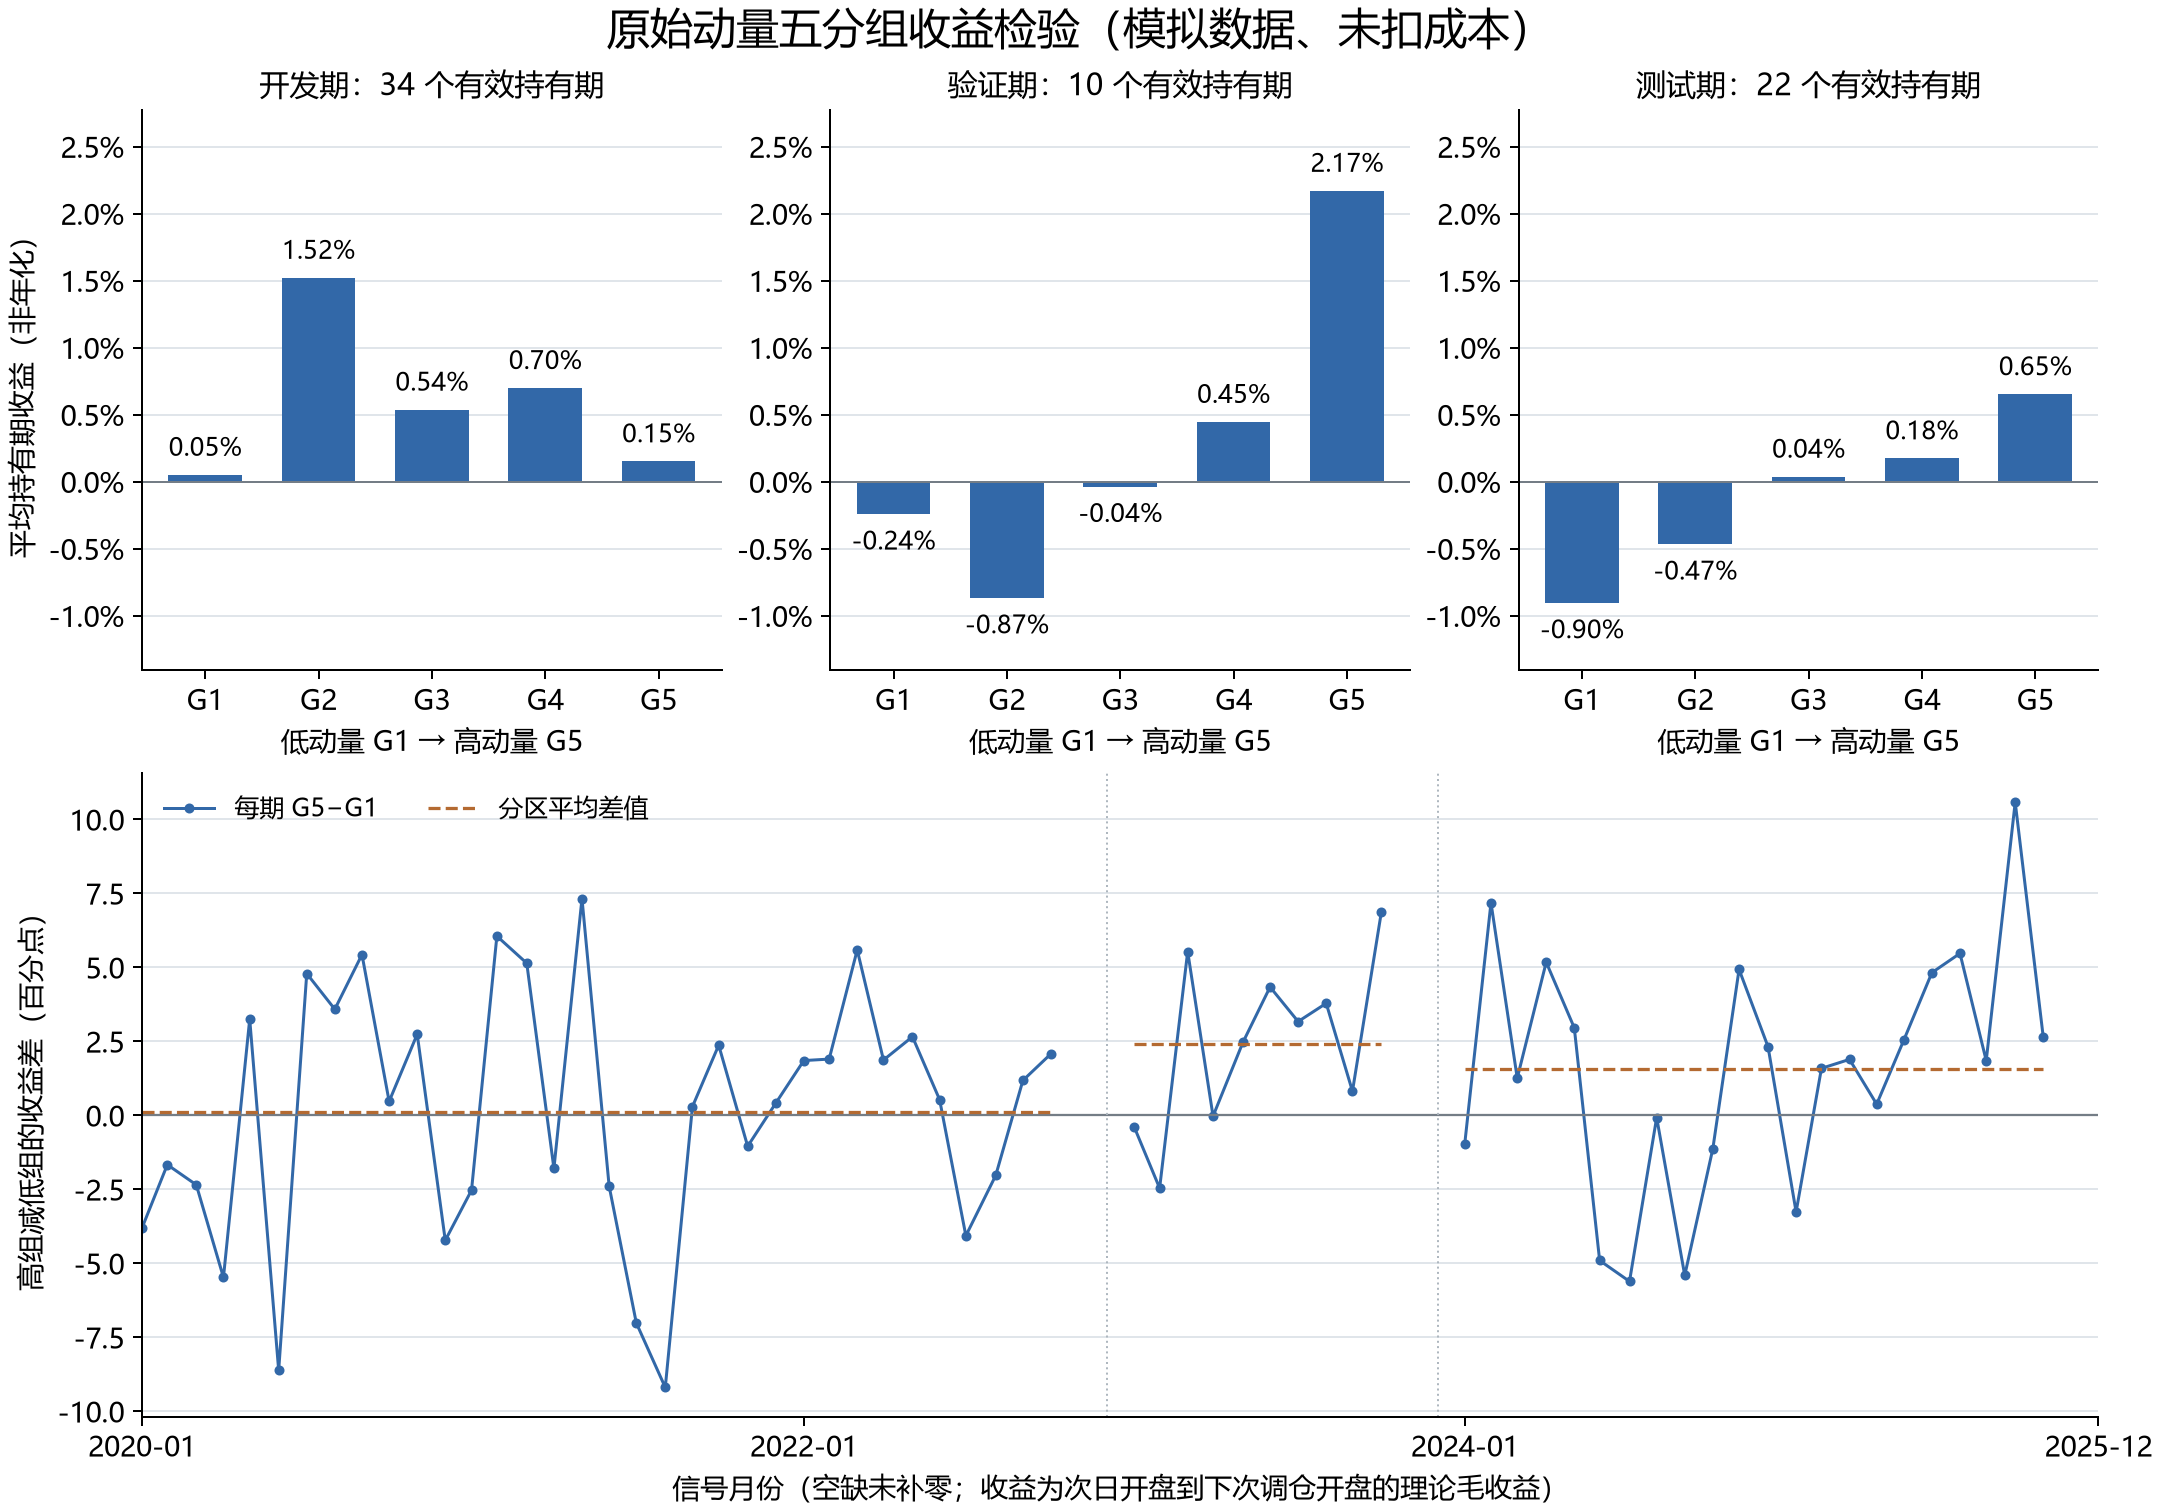

In [8]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/first_demo_20261107/lesson09_quintile_returns/quintile_returns.png')))

## 运行复核

以上实现已在干净内核中按顺序执行；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。